# Validação de carregamento de dataset a partir de config

Este notebook carrega o dataset definido em um arquivo `.yaml` de `experiment` ou `benchmark` e permite navegar pelas amostras por índice, exibindo:

1. imagem de exemplo;
2. máscara de segmentação;
3. imagem e máscara sobrepostas, com opacidade da máscara parametrizável.

Edite a célula **Parâmetros** abaixo e rode o notebook de cima para baixo.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('../')

from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from src.utils import instantiate_from_config

## Parâmetros

- `CONFIG_PATH`: caminho para um arquivo `.yaml` de `experiment` ou `benchmark` (`configs/experiment/**/*.yaml` ou `configs/benchmark/*.yaml`).
- `DATASET_NAME`: nome do dataset (chave sob `datasets` no config) a ser selecionado. **Só é usado quando `CONFIG_PATH` é um `benchmark`** — para `experiment` é ignorado, pois nesse caso o dataset já está definido diretamente em `data`.
- `SPLIT`: split do dataset a ser carregado (`train`, `validation` ou `test`).

Os parâmetros abaixo sobrescrevem, programaticamente, o que estiver no `.yaml` (deixe `None` para manter o valor do arquivo de configuração):

- `SPLIT_MODE`: `'legado'` reproduz o split histórico (coluna `split_legado`); `'seed'` divide o pool de frames em tempo de execução por `paciente_id`.
- `SPLIT_SEED`: seed usada quando `SPLIT_MODE='seed'` — variar este valor permite testar novos splits sem editar o `.yaml`.
- `TARGET_TYPE`: modalidade do alvo (`'mask'` ou `'points'`).
- `TARGET_VARIANT`: variante da máscara (`'raw'`, `'binary_c2_c4'`, `'multiclass_c2_c4'` ou `'multiclass_all'`).

In [3]:
CONFIG_PATH = "../configs/experiment/unet/vfss-inca-unet-c2-c4-only.yaml"
DATASET_NAME = "inca"  # ignorado se CONFIG_PATH for um `experiment`
SPLIT = "train"  # "train" | "validation" | "test"

# Overrides programáticos (deixe None para manter o valor do .yaml)
SPLIT_MODE = None  # None | "legado" | "seed"
SPLIT_SEED = None  # None | int, usado apenas quando SPLIT_MODE == "seed"
TARGET_TYPE = None  # None | "mask" | "points"
TARGET_VARIANT = None  # None | "raw" | "binary_c2_c4" | "multiclass_c2_c4" | "multiclass_all"

## Carregamento do config de dados

`load_data_config` lê o `.yaml`, identifica se é `experiment` (usa a chave `data`) ou `benchmark` (usa a entrada de `datasets` cuja chave é `DATASET_NAME`) e devolve o config (`target` + `params`) do `DataModuleFromConfig` correspondente.

In [4]:
def load_data_config(config_path: str, dataset_name: str = None):
    """Read an experiment/benchmark yaml and return the data module config dict."""
    resolved_path = Path(config_path).expanduser().resolve()
    if not resolved_path.exists():
        raise FileNotFoundError(f"Config file not found: {resolved_path}")

    config = OmegaConf.load(str(resolved_path))
    config_type = config.get("type")

    if config_type == "experiment":
        if "data" not in config:
            raise ValueError(f"Missing required field `data` in {resolved_path}")
        data_cfg = config.data

    elif config_type == "benchmark":
        datasets = config.get("datasets", [])
        available = [next(iter(entry.keys())) for entry in datasets]
        if not dataset_name:
            raise ValueError(
                f"`dataset_name` must be provided for benchmark configs. "
                f"Available datasets in {resolved_path}: {available}"
            )
        matches = [entry[dataset_name] for entry in datasets if dataset_name in entry]
        if not matches:
            raise ValueError(
                f"Dataset `{dataset_name}` not found under `datasets` in {resolved_path}. "
                f"Available: {available}"
            )
        data_cfg = matches[0]

    else:
        raise ValueError(f"Unsupported config `type`: {config_type!r} in {resolved_path}")

    return OmegaConf.to_container(data_cfg, resolve=True), config_type


data_cfg, config_type = load_data_config(CONFIG_PATH, DATASET_NAME)

# Aplica os overrides programáticos (SPLIT_MODE/SPLIT_SEED/TARGET_TYPE/TARGET_VARIANT)
# por cima do que estiver definido no .yaml, sem precisar editar o arquivo.
overrides = {
    "split_mode": SPLIT_MODE,
    "split_seed": SPLIT_SEED,
    "target_type": TARGET_TYPE,
    "target_variant": TARGET_VARIANT,
}
overrides = {k: v for k, v in overrides.items() if v is not None}
if overrides:
    data_cfg["params"]["shared_dataset_params"].update(overrides)

print(f"Config type: {config_type}")
print(OmegaConf.to_yaml(data_cfg))

Config type: experiment
target: src.data.base.DataModuleFromConfig
params:
  batch_size: 8
  num_workers: 8
  wrap: false
  shared_dataset_params:
    dataset_path: /data_ssd/caioseda/data/dataset_inca_all_frames/
    size: 256
    window_size: 1
    stride: 1
    repeat_channels: true
    target_variant: binary_c2_c4
  train:
    target: src.data.vfss_v2.VFSSIncaTrain
  validation:
    target: src.data.vfss_v2.VFSSIncaVal
  test:
    target: src.data.vfss_v2.VFSSIncaTest



## Instanciação do datamodule e seleção do split

In [5]:
datamodule = instantiate_from_config(data_cfg)
datamodule.setup()

print(f"Splits disponíveis: {list(datamodule.datasets.keys())}")

if SPLIT not in datamodule.datasets:
    raise KeyError(f"Split `{SPLIT}` não configurado neste dataset. Disponíveis: {list(datamodule.datasets.keys())}")

dataset = datamodule.datasets[SPLIT]
print(f"Split `{SPLIT}`: {len(dataset)} amostras")

sample = dataset[0]
print(f"Chaves da amostra: {list(sample.keys())}")
print(f"image shape: {tuple(sample['image'].shape)}, dtype: {sample['image'].dtype}")
print(f"segmentation shape: {tuple(sample['segmentation'].shape)}, dtype: {sample['segmentation'].dtype}")

Splits disponíveis: ['train', 'validation', 'test']
Split `train`: 559 amostras
Chaves da amostra: ['image', 'segmentation', 'metadata']
image shape: (3, 256, 256), dtype: torch.float32
segmentation shape: (256, 256), dtype: torch.int64


## Visualização por índice

`show_sample(dataset, idx, mask_alpha)` exibe a imagem, a máscara e a sobreposição das duas (opacidade da máscara controlada por `mask_alpha`).

In [6]:
def _select_center_frame(image: torch.Tensor) -> torch.Tensor:
    """Reduce a (window, C, H, W) window tensor to its center (C, H, W) frame."""
    if image.ndim == 4:
        return image[image.shape[0] // 2]
    return image


def _to_display_image(image: torch.Tensor) -> np.ndarray:
    """Convert a (C, H, W) tensor into an (H, W[, 3]) numpy array in [0, 1] for imshow."""
    image = _select_center_frame(image).detach().cpu().float()

    if image.min() < 0:
        image = (image + 1.0) / 2.0  # assume [-1, 1] normalization
    image = image.clamp(0, 1)

    if image.shape[0] == 1:
        return image.squeeze(0).numpy()
    if image.shape[0] == 3:
        return image.permute(1, 2, 0).numpy()
    return image.mean(dim=0).numpy()


def _to_display_mask(mask: torch.Tensor) -> np.ndarray:
    mask = mask.detach().cpu()
    if mask.ndim == 3 and mask.shape[0] == 1:
        mask = mask.squeeze(0)
    return mask.numpy()


def show_sample(dataset, idx: int, mask_alpha: float = 0.5, mask_cmap: str = "autumn", figsize=(15, 5)):
    sample = dataset[idx]
    image_np = _to_display_image(sample["image"])
    mask_np = _to_display_mask(sample["segmentation"])
    image_cmap = "gray" if image_np.ndim == 2 else None
    mask_vmax = max(int(mask_np.max()), 1)

    fig, axes = plt.subplots(1, 3, figsize=figsize)

    axes[0].imshow(image_np, cmap=image_cmap)
    axes[0].set_title("Imagem")
    axes[0].axis("off")

    axes[1].imshow(mask_np, cmap="gray", vmin=0, vmax=mask_vmax)
    axes[1].set_title("Máscara")
    axes[1].axis("off")

    axes[2].imshow(image_np, cmap=image_cmap)
    masked = np.ma.masked_where(mask_np == 0, mask_np)
    axes[2].imshow(masked, cmap=mask_cmap, alpha=mask_alpha, vmin=0, vmax=mask_vmax)
    axes[2].set_title(f"Sobreposição (alpha={mask_alpha})")
    axes[2].axis("off")

    metadata = sample.get("metadata")
    title = f"idx={idx}"
    if metadata:
        extra = " | ".join(
            f"{k}={metadata[k]}"
            for k in ("video_id", "frame_id", "split", "selected_labeler", "target_variant")
            if k in metadata
        )
        if extra:
            title += f" | {extra}"
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

    return sample

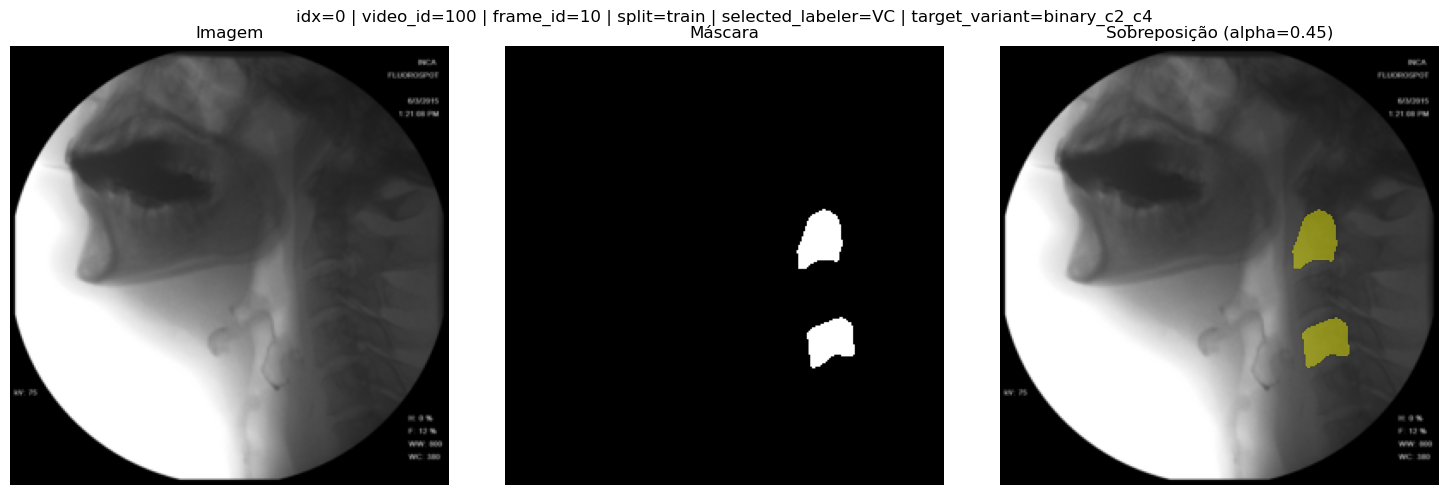

In [7]:
_ = show_sample(dataset, idx=0, mask_alpha=0.45)

## (Opcional) navegação interativa com sliders

Requer `ipywidgets` (`pip install ipywidgets`). Se não estiver instalado, use a célula acima manualmente, alterando `idx` e `mask_alpha`.

In [8]:
try:
    import ipywidgets as widgets

    widgets.interact(
        lambda idx, mask_alpha: show_sample(dataset, idx=idx, mask_alpha=mask_alpha),
        idx=widgets.IntSlider(min=0, max=len(dataset) - 1, step=1, value=0, description="idx"),
        mask_alpha=widgets.FloatSlider(min=0.0, max=1.0, step=0.05, value=0.45, description="mask alpha"),
    )
except ImportError:
    print(
        "ipywidgets não está instalado; use show_sample(dataset, idx=..., mask_alpha=...) manualmente, "
        "ou instale com `pip install ipywidgets` para sliders interativos."
    )

ipywidgets não está instalado; use show_sample(dataset, idx=..., mask_alpha=...) manualmente, ou instale com `pip install ipywidgets` para sliders interativos.


## Uso 100% programático (sem `.yaml`)

O dataset novo é um pool único de frames (`inca-video-frame-dataset.csv`). É possível
explorar/dividir esse pool diretamente em notebook, sem passar por nenhum arquivo de
configuração:

- `split_by_patient(df, seed=...)` gera uma divisão train/val/test respeitando
  `paciente_id` (nenhum paciente cai em mais de um split) — variar `seed` permite testar
  splits diferentes.
- `with_target_variant(df, ...)` / `with_target_type(df, ...)` trocam, respectivamente, a
  variante da máscara (`raw`, `binary_c2_c4`, `multiclass_c2_c4`, `multiclass_all`) e a
  modalidade do alvo (`mask`, `points`), recalculando `target_path`.

In [9]:
from src.data.vfss_v2 import (
    VFSSWindowImageDataset,
    load_video_frame_dataframe,
    split_by_patient,
    with_target_variant,
    with_target_type,
)

DATASET_PATH = "/data_ssd/caioseda/data/dataset_inca_all_frames/"

pool_df = load_video_frame_dataframe(DATASET_PATH)
print(f"Pool completo: {len(pool_df)} frames, {pool_df['paciente_id'].nunique()} pacientes")

# Divide o pool por paciente com um seed à escolha (registre o seed usado no log do experimento).
split_df = split_by_patient(pool_df, seed=123, ratios=(0.7, 0.15, 0.15))
print(split_df['split'].value_counts())

# Troca de variante de máscara / modalidade diretamente no DataFrame.
df_bin = with_target_variant(pool_df, "binary_c2_c4")
df_points = with_target_type(pool_df, "points")
print(df_bin.loc[0, "target_path"], "|", df_points.loc[0, "target_path"])

# O Dataset também aceita split_mode="seed" diretamente, sem precisar montar o DataFrame à mão:
ds_new_split = VFSSWindowImageDataset(
    dataset_path=DATASET_PATH,
    split="train",
    split_mode="seed",
    split_seed=123,
    target_variant="binary_c2_c4",
)
print(f"VFSSWindowImageDataset(split_mode='seed', split_seed=123): {len(ds_new_split)} amostras de treino")

Pool completo: 961 frames, 114 pacientes
split
train    706
val      151
test     104
Name: count, dtype: int64
targets/mask/binary_c2_c4/VC/v100_f10.tif | targets/points/raw/VC/v100_f10.tif
VFSSWindowImageDataset(split_mode='seed', split_seed=123): 706 amostras de treino


O mesmo vale para o pool da UNM (`unm-video-frame-dataset.csv`), que também tem
`paciente_id` (cada paciente tem exatamente um vídeo nesse dataset). A UNM expõe suas
próprias variantes de máscara (`UNM_TARGET_VARIANTS`, que incluem
`binary_c2_c3_c4`/`multiclass_c2_c3_c4`, ausentes na INCA).
`VFSSUnmWindowImageDataset`/`VFSSUnmTrain`/`VFSSUnmVal`/`VFSSUnmTest` (`src.data.unm`) já
vêm configurados com esses defaults.

In [10]:
from src.data.unm import VFSSUnmTrain, UNM_TARGET_VARIANTS

UNM_DATASET_PATH = "/data_ssd/caioseda/data/dataset_unm"

unm_pool_df = load_video_frame_dataframe(UNM_DATASET_PATH, "unm-video-frame-dataset.csv")
print(f"Pool UNM: {len(unm_pool_df)} frames, {unm_pool_df['paciente_id'].nunique()} pacientes")

unm_split_df = split_by_patient(unm_pool_df, seed=123, ratios=(0.7, 0.1, 0.2))
print(unm_split_df['split'].value_counts())

unm_df_bin = with_target_variant(unm_pool_df, "binary_c2_c3_c4", valid_variants=UNM_TARGET_VARIANTS)
print(unm_df_bin.loc[0, "target_path"])

unm_train_new_split = VFSSUnmTrain(
    dataset_path=UNM_DATASET_PATH,
    split_mode="seed",
    split_seed=123,
    target_variant="binary_c2_c3_c4",
)
print(f"VFSSUnmTrain(split_mode='seed', split_seed=123): {len(unm_train_new_split)} amostras de treino")

Pool UNM: 325 frames, 35 pacientes
split
train    236
test      52
val       37
Name: count, dtype: int64
targets/mask/binary_c2_c3_c4/VC/v025_f242.tif
VFSSUnmTrain(split_mode='seed', split_seed=123): 236 amostras de treino
